# Understand and test the SODE equations

This is a **small mathematical verification notebook**, not a reconstruction of the missing original La Palma dynamic case. It calls the original `event_inputs` and `integrate_event` functions on clearly declared artificial parameters. No production labels or accepted results are changed.

With $\Delta f=f-f_0$, survivor energy $E$, loss $L$ and damping $D$, the source solves
$$\dot{\Delta f}=\frac{f_0}{2E}\left(\sum_i r_i-L-D\Delta f\right),$$
$$\dot q_i=v_i,\qquad a_{2i}\dot v_i=-q_i-a_{1i}v_i-\Delta f,$$
$$r_i=\min\{G_i(q_i+b_{1i}v_i),\rho_i\}.$$
$q_i$ is in Hz; $v_i$ is Hz/s; $a_1,b_1$ are seconds; $a_2$ is seconds squared. The upper-only `minimum` is intentional: changing it to a two-sided clip or adding anti-windup changes the source model.

The numerical method is LSODA, with the original dense-output local-minimum refinement and coarse/fine checks. A 40-Hz stopping event censors a trajectory; an endpoint that has not settled is not silently promoted to a resolved nadir.

In [1]:
from pathlib import Path
import json, math
import numpy as np
from scipy.integrate import solve_ivp
from scipy.optimize import minimize_scalar
import matplotlib.pyplot as plt

for ROOT in (Path.cwd().resolve(),*Path.cwd().resolve().parents):
    if (ROOT/'GAMS_LaPalma/START_LAPALMA.gms').is_file():break
else:raise FileNotFoundError('Open this notebook inside the extracted repository.')
F0=50.0
NUMERIC=dict(method='LSODA',rtol=1e-8,atol=1e-10,max_step=.20,
             output_step=.02,duration=60.,extension=120.,stop_hz=40.,
             settle_range_hz=.005,settle_slope_hz_s=1e-4,
             nadir_refine_tol_hz=1e-3,boundary_hz=1e-4)
# Explicit ARTIFICIAL fixture: eleven array slots, two online units, one survivor.
# These values are NOT the missing original La Palma a1/a2/b1 parameter vectors.
PMAX=np.array([10.,20.]+[10.]*9)
EUNIT=np.array([50.,100.]+[10.]*9)
GAIN=np.zeros(11)
A1=np.full(11,2.0);A2=np.ones(11);B1=np.full(11,0.5)
CASE={'damping_fraction_per_hz':1.0/15.0}
power=np.array([5.,10.]+[0.]*9)
demand=15.;outage=0


## Original source functions
The next cell is an exact copy of the two source definitions, not a newly substituted ODE implementation. The fixture defines their globals explicitly. Their original scientific case file is still required for production La Palma trajectory replay.

In [2]:
def event_inputs(power, demand_mw, outage_index, commitment=None):
    power=np.asarray(power,float).copy();demand_mw=float(demand_mw);j=int(outage_index)
    if power.shape!=(11,) or not np.isfinite(power).all() or demand_mw<0:raise ValueError('Invalid event input')
    on=(power>1e-8) if commitment is None else np.rint(np.asarray(commitment,float)).astype(bool)
    if on.shape!=(11,) or not on[j] or power[j]<=1e-8:raise ValueError('Outage must remove an online producing unit')
    if np.any(power<-1e-6) or np.any(power>PMAX*on+1e-6):raise ValueError('Invalid pre-event generator outputs')
    survive=on.copy();survive[j]=False
    idx=np.flatnonzero(survive);E=float(EUNIT[survive].sum());rho=np.maximum(PMAX-power,0)[idx]
    return dict(power=power,online=on,survive=survive,index=idx,E=E,rho=rho,
        gain=GAIN[idx],a1=A1[idx],a2=A2[idx],b1=B1[idx],loss=float(power[j]),
        damping=demand_mw*CASE['damping_fraction_per_hz'],demand=demand_mw,outage=j)

def integrate_event(power,demand_mw,outage_index,commitment=None,refined=False,return_trace=False):
    v=event_inputs(power,demand_mw,outage_index,commitment)
    if v['E']<=0:raise ValueError('No surviving inertia; no fictitious epsilon inertia is inserted')
    n=len(v['index']);rtol=NUMERIC['rtol']*(.1 if refined else 1.)
    atol=NUMERIC['atol']*(.1 if refined else 1.)
    step=NUMERIC['output_step']*(.5 if refined else 1.)
    mx=NUMERIC['max_step']*(.5 if refined else 1.)
    def response(y):return np.minimum(v['gain']*(y[1:1+n]+v['b1']*y[1+n:]),v['rho'])
    def rhs(t,y):
        df=y[0];q=y[1:1+n];dq=y[1+n:]
        dfdt=F0/(2*v['E'])*(response(y).sum()-v['loss']-v['damping']*df)
        ddq=(-q-v['a1']*dq-df)/v['a2']
        return np.concatenate(([dfdt],dq,ddq))
    def stop(t,y):return F0+y[0]-NUMERIC['stop_hz']
    stop.terminal=True;stop.direction=-1
    y0=np.zeros(1+2*n);duration=NUMERIC['duration'];pieces=[];start=0.;state=y0
    while True:
        sol=solve_ivp(rhs,(start,duration),state,method=NUMERIC['method'],rtol=rtol,atol=atol,
                      max_step=mx,dense_output=True,events=stop)
        if not sol.success or not np.isfinite(sol.y).all():raise RuntimeError(sol.message)
        end=float(sol.t[-1]);grid=np.linspace(start,end,max(2,int(np.ceil((end-start)/step))+1))
        Y=sol.sol(grid);frequency=F0+Y[0];pieces.append((grid,Y,sol))
        censored=bool(sol.t_events[0].size)
        tail=grid>=max(start,end-5.)
        slope=float(rhs(end,Y[:,-1])[0]);range_=float(np.ptp(frequency[tail]))
        settled=(not censored and end>=10 and range_<=NUMERIC['settle_range_hz'] and abs(slope)<=NUMERIC['settle_slope_hz_s'])
        if censored or settled or duration>=NUMERIC['extension']:break
        start=end;state=Y[:,-1];duration=NUMERIC['extension']
    times=np.concatenate([g if k==0 else g[1:] for k,(g,_,__) in enumerate(pieces)])
    states=np.concatenate([y if k==0 else y[:,1:] for k,(_,y,__) in enumerate(pieces)],axis=1)
    freq=F0+states[0];nadir=float(freq.min());tn=float(times[freq.argmin()])
    # Refine each sampled local minimum using the dense interpolation of its own interval.
    for grid,Y,sol in pieces:
        f=F0+Y[0]
        for k in np.flatnonzero((f[1:-1]<f[:-2])&(f[1:-1]<=f[2:]))+1:
            opt=minimize_scalar(lambda t:float(F0+sol.sol(t)[0]),bounds=(grid[k-1],grid[k+1]),method='bounded',options={'xatol':1e-9})
            if opt.fun<nadir:nadir=float(opt.fun);tn=float(opt.x)
    rtotal=np.array([response(y).sum() for y in states.T])
    record=dict(minimum_observed_hz=nadir,time_min_s=tn,endpoint_hz=float(freq[-1]),
        initial_rocof_hz_s=float(rhs(0,y0)[0]),settled=bool(settled),censored=bool(censored),
        simulated_seconds=float(times[-1]),tail_range_hz=range_,tail_slope_hz_s=slope,
        loss_mw=v['loss'],inertia_mws=v['E'],gain_mw_hz=float(v['gain'].sum()),
        reserve_mw=float(v['rho'].sum()),gain_source=float(F0*v['gain'].sum()),demand_mw=float(demand_mw))
    return record,dict(time_s=times,frequency_hz=freq,response_mw=rtotal) if return_trace else None


## 1. Zero-response closed-form test
Here $G=0$, $E=100$ MW s, $L=5$ MW, $D=1$ MW/Hz and $f_0=50$ Hz. The scalar equation has the exact solution
$$f(t)=50-5\left(1-\exp(-0.25t)\right).$$
Initial RoCoF is $-1.25$ Hz/s and the equilibrium is 45 Hz. The purpose is to verify the sign, frequency conversion and integrator, not to present this artificial system as La Palma.

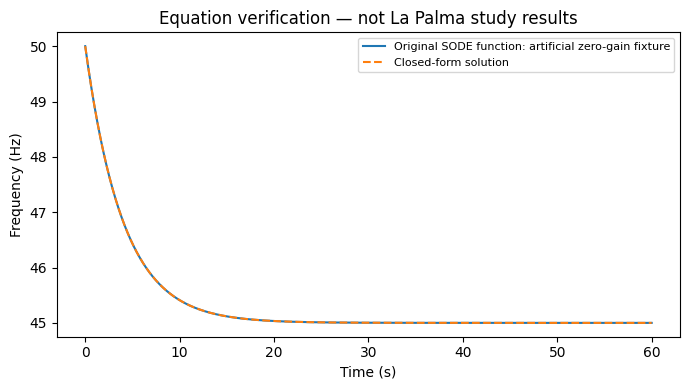

PASS: maximum trajectory error (Hz) = 3.204654319688416e-09


In [3]:
record,trace=integrate_event(power,demand,outage,return_trace=True)
exact=50.-5.*(1.-np.exp(-.25*trace['time_s']))
error=float(np.max(np.abs(trace['frequency_hz']-exact)))
assert error<1e-6,error
assert abs(record['initial_rocof_hz_s']+1.25)<1e-12
assert record['settled'] and not record['censored']
fig,ax=plt.subplots(figsize=(7,4))
ax.plot(trace['time_s'],trace['frequency_hz'],label='Original SODE function: artificial zero-gain fixture')
ax.plot(trace['time_s'],exact,linestyle='--',label='Closed-form solution')
ax.set(xlabel='Time (s)',ylabel='Frequency (Hz)',title='Equation verification — not La Palma study results')
ax.legend(fontsize=8);fig.tight_layout();plt.show()
print('PASS: maximum trajectory error (Hz) =',error)


## 2. Finite governor gain and individual headroom
For survivor gain $G=2$ MW/Hz and no active cap, equilibrium is $50-L/(D+G)=48.333\ldots$ Hz. A second test reduces survivor headroom to 2 MW; then its sustained contribution cannot exceed 2 MW, and equilibrium is $50-(L-2)/D=47$ Hz.

The coarse/fine comparison checks numerical consistency. It is not validation against measured system frequency.

In [4]:
GAIN[1]=2.
base,bt=integrate_event(power,demand,outage,return_trace=True)
fine,ft=integrate_event(power,demand,outage,refined=True,return_trace=True)
refinement_error=abs(base['minimum_observed_hz']-fine['minimum_observed_hz'])
assert refinement_error<=NUMERIC['nadir_refine_tol_hz']
assert abs(fine['endpoint_hz']-(50.-5./3.))<1e-3
assert ft['response_mw'].max()<=10.+1e-10
PMAX[1]=12. # artificial capped fixture, NOT a change to shipped La Palma inputs
capped,ct=integrate_event(power,demand,outage,refined=True,return_trace=True)
assert ct['response_mw'].max()<=2.+1e-10
assert abs(capped['endpoint_hz']-47.)<1e-3
print('PASS: finite-gain equilibrium, numerical refinement and individual response cap.')
# The original function must reject zero surviving inertia, not insert an epsilon.
saved=EUNIT.copy();EUNIT[1]=0
try:
    integrate_event(power,demand,outage)
except ValueError as exc:
    assert 'No surviving inertia' in str(exc)
else:raise AssertionError('Zero surviving inertia was not rejected.')
finally:EUNIT=saved
report={'status':'PASS','fixture_scope':'ARTIFICIAL: not original La Palma governor parameters',
        'zero_gain_trajectory_max_error_hz':error,'finite_gain_refinement_error_hz':refinement_error,
        'upper_cap_mw':2.0,'zero_inertia_rejected':True,'original_dynamic_case_replay':'NOT RUN'}
out=ROOT/'verification/local_reports';out.mkdir(parents=True,exist_ok=True)
(out/'02_sode_equations.json').write_text(json.dumps(report,indent=2)+'\n')
print('Original physical-case replay remains NOT RUN; no production labels were generated.')


PASS: finite-gain equilibrium, numerical refinement and individual response cap.
Original physical-case replay remains NOT RUN; no production labels were generated.
